# 11 · Evaluación final: ¿qué se sostiene fuera de muestra?

En este notebook se evalúa en el test (enero a junio de 2025) lo decidido en desarrollo (julio a diciembre de 2024): las 121,366 mezclas de 2 y 3 modelos y el modelo final elegido entre ellas (notebook 10). Primero se muestra el resultado del modelo final; después, cómo se comportan las mezclas en desarrollo y en el test, con la mejor de desarrollo y la mejor del test; luego se comparan cuatro criterios de elección, entre ellos el error medio que se usaba al principio del proyecto. Con el modelo final, se revisan el ahorro, la estabilidad, dónde gana y pierde, los intervalos y los nodos.

**Medición.** El error es el MAE, en MXN/MWh, acompañado casi siempre del cambio porcentual contra el MDA (negativo es mejor). Para evaluar si la ventaja es consistente se usa la prueba de Giacomini–White: su *p* es la probabilidad de observar una diferencia así de consistente si los dos modelos fueran igual de buenos; menor a 0.05 hace difícil que sea suerte. Solo el modelo final tiene una prueba formal; con tantas candidatas, los *p* de las demás son contexto.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import features2 as f2, exp, gb2, referencias as rf, escalera, picos, mezclas as mz
from pml.data import cargar_largo, matriz
from pml.features import feriados_mx
from scipy.stats import spearmanr
from pml.metrics import mae, rmse, gw_test, mae_por_bloque
R = rf.cargar()                                         # los pronósticos establecidos en los notebooks 05 a 08
c0, cb, Y, X = R.c0, R.cb, R.Y, R.X
DEV, TEST, DIAS = exp.idx_dev(), exp.idx_test(), exp.dias_eval(c0)
Yt, Xt = f2._t(cb)
CACHE = ROOT / 'data/processed/exp_cache'
fd = lambda d, idx: d.loc[idx].values
md_ = lambda M, idx: mae(fd(Y, idx), fd(M, idx))                                        # MAE en MXN/MWh
cambio = lambda M, idx: 100 * (md_(M, idx) / md_(X, idx) - 1)                           # % contra el MDA (negativo = menos error)
meses_mejor = lambda M: int((mae_por_bloque(Y, M, TEST) < mae_por_bloque(Y, X, TEST)).sum())
inv_s = lambda M: f2.inv(M + Xt.loc[M.index], cb)
CF = pickle.loads((CACHE / 'nb11_conjunto_final.pkl').read_bytes())     # lo que dejó el notebook 10, fijado en desarrollo
POOL, FINAL_N = CF['pool'], CF['final']; FINAL = POOL[FINAL_N]
RED = pickle.loads((CACHE / 'nb09_red.pkl').read_bytes())
# Todas las mezclas de 2 y 3 modelos del notebook 10 (caché): su cambio contra el MDA en cada mes, en desarrollo y en el test
PASOS = escalera.cargar_pasos(R)
FC = {'MDA': X, **{f'{k} · {p}': P for k, d in PASOS.items() for p, P in d.items() if P is not None}}
MZ = mz.evaluar(Y, X, FC, DEV, TEST); NOM, CANDS = MZ['nombres'], MZ['cands']
ARR = np.stack([FC[k].loc[DIAS].values for k in NOM])
pron = lambda r: pd.DataFrame(mz.pronostico(ARR, CANDS[r]), index=DIAS, columns=X.columns)      # el pronóstico de la candidata r
nom = lambda r: mz.nombre(NOM, CANDS[r])
CAL = mz.calificaciones(MZ['mensual'].iloc[:, :6], MZ['desarrollo'])                          # calificación con cada criterio, solo desarrollo
ELEG = {c: int(np.argmin(CAL[c].values)) for c in CAL}                                        # la candidata que elige cada criterio
R_DEV, R_TEST = ELEG['error medio'], int(np.argmin(MZ['test'].values))                        # la mejor de desarrollo (error medio) y la mejor del test (se sabe después)
assert nom(ELEG['peor mes']) == FINAL_N                                                       # el modelo final es el que elige el peor mes
print('configuraciones registradas a lo largo del proyecto:', len(pd.read_csv(REP / 'experimentos.csv')))
print(f'mezclas candidatas: {len(CANDS):,} | modelo final (peor mes): {FINAL_N}')

configuraciones registradas a lo largo del proyecto: 383
mezclas candidatas: 121,366 | modelo final (peor mes): 0.5·LEAR en proporción · + nodos + 0.4·GB · todas las variables + 0.1·red sin MDA · todas las variables


## 1. El resultado del modelo final

In [2]:
# El modelo final (la mezcla elegida con el peor mes en el notebook 10, fijada en desarrollo) contra el MDA: la prueba formal del test
pf = gw_test(fd(Y, TEST), fd(FINAL, TEST), fd(X, TEST))['p']
print(f"modelo final: {FINAL_N}")
print(f"  test:        MAE {md_(FINAL, TEST):.1f} MXN/MWh contra {md_(X, TEST):.1f} del MDA ({cambio(FINAL, TEST):+.1f}%), mejor en {meses_mejor(FINAL)} de 6 meses, p = {pf:.3f}")
print(f"  desarrollo:  MAE {md_(FINAL, DEV):.1f} MXN/MWh contra {md_(X, DEV):.1f} del MDA ({cambio(FINAL, DEV):+.1f}%)")
# Las mezclas en el test: las 10 mejores, más el modelo final (peor mes) y la mejor de desarrollo (error medio) si no están entre ellas
pico = Y.loc[TEST].max(axis=1) > 3000
ORDEN_T = np.argsort(MZ['test'].values)
SEL_R = list(ORDEN_T[:10]) + [r for r in (ELEG['peor mes'], R_DEV) if r not in ORDEN_T[:10]]
lugar = lambda serie, r: int((serie < serie[r]).sum()) + 1
TP = pd.DataFrame({nom(r): {'lugar en el test': lugar(MZ['test'], r), 'lugar en desarrollo': lugar(MZ['desarrollo'], r), 'MAE desarrollo': md_(X, DEV) * (1 + MZ['desarrollo'][r] / 100),
                            'desarrollo vs MDA (%)': MZ['desarrollo'][r], 'peor mes (%)': CAL['peor mes'][r],
                            'MAE test': md_(X, TEST) * (1 + MZ['test'][r] / 100), 'test vs MDA (%)': MZ['test'][r]} for r in SEL_R}).T
TP.loc['MDA'] = [None, None, md_(X, DEV), 0.0, 0.0, md_(X, TEST), 0.0]
display(TP.astype(float).round(1)); TP.astype(float).round(3).to_csv(REP / '11_conjunto_test.csv')
print(f"candidatas que le ganan al MDA en el test: {(MZ['test'] < 0).sum():,} de {len(CANDS):,} | correlación entre el orden en desarrollo y en el test: {MZ['desarrollo'].corr(MZ['test'], method='spearman'):.2f}")

modelo final: 0.5·LEAR en proporción · + nodos + 0.4·GB · todas las variables + 0.1·red sin MDA · todas las variables
  test:        MAE 170.7 MXN/MWh contra 183.4 del MDA (-6.9%), mejor en 5 de 6 meses, p = 0.000
  desarrollo:  MAE 209.6 MXN/MWh contra 221.6 del MDA (-5.4%)


,lugar en el test,lugar en desarrollo,MAE desarrollo,desarrollo vs MDA (%),peor mes (%),MAE test,test vs MDA (%)
0.4·LEAR en proporción · PCA + 0.5·GB · + modelado estadístico + 0.1·red sin MDA · todas las variables,1.0,2190.0,210.2,-5.1,-2.5,169.5,-7.6
0.4·LEAR en proporción · PCA + 0.5·GB · todas las variables + 0.1·red sin MDA · todas las variables,2.0,2191.0,210.2,-5.1,-1.7,169.6,-7.5
0.5·LEAR en proporción · PCA + 0.4·GB · + modelado estadístico + 0.1·red sin MDA · todas las variables,3.0,1453.0,209.8,-5.3,-2.6,169.6,-7.5
0.5·LEAR en proporción · PCA + 0.4·GB · todas las variables + 0.1·red sin MDA · todas las variables,4.0,1087.0,209.6,-5.4,-2.6,169.6,-7.5
0.4·LEAR en proporción · PCA + 0.4·GB · + modelado estadístico + 0.2·red sin MDA · todas las variables,5.0,516.0,209.1,-5.7,-1.0,169.7,-7.5
0.3·LEAR en proporción · PCA + 0.6·GB · + modelado estadístico + 0.1·red sin MDA · todas las variables,6.0,3535.0,211.0,-4.8,-2.3,169.7,-7.5
0.5·LEAR en proporción · PCA + 0.3·GB · + modelado estadístico + 0.2·red sin MDA · todas las variables,7.0,239.0,208.7,-5.8,-1.3,169.8,-7.4
0.3·LEAR en proporción · PCA + 0.5·GB · + modelado estadístico + 0.2·red sin MDA · todas las variables,8.0,1403.0,209.8,-5.4,-0.2,169.9,-7.3
0.3·LEAR en proporción · PCA + 0.6·GB · todas las variables + 0.1·red sin MDA · todas las variables,9.0,3967.0,211.3,-4.7,-0.6,169.9,-7.3
0.5·LEAR en proporción · PCA + 0.3·GB · todas las variables + 0.2·red sin MDA · todas las variables,10.0,31.0,208.0,-6.1,-3.0,169.9,-7.3


candidatas que le ganan al MDA en el test: 87,028 de 121,366 | correlación entre el orden en desarrollo y en el test: 0.64


El modelo final, 0.5·LEAR en proporción con nodos + 0.4·GB con todas las variables + 0.1·red sin MDA con todas las variables, obtiene 170.7 MXN/MWh en el test contra 183.4 del MDA: 6.9% menos error, mejor en 5 de 6 meses, con *p* < 0.001. En desarrollo tenía 209.6 (−5.4%).

Mantiene en el test una ventaja mayor que la que tenía en desarrollo. La tabla muestra las 10 mejores mezclas del test, el modelo final y la mejor de desarrollo; de las 121,366 candidatas, 87,028 le ganan al MDA en el test.

## 2. Todos los modelos del conjunto

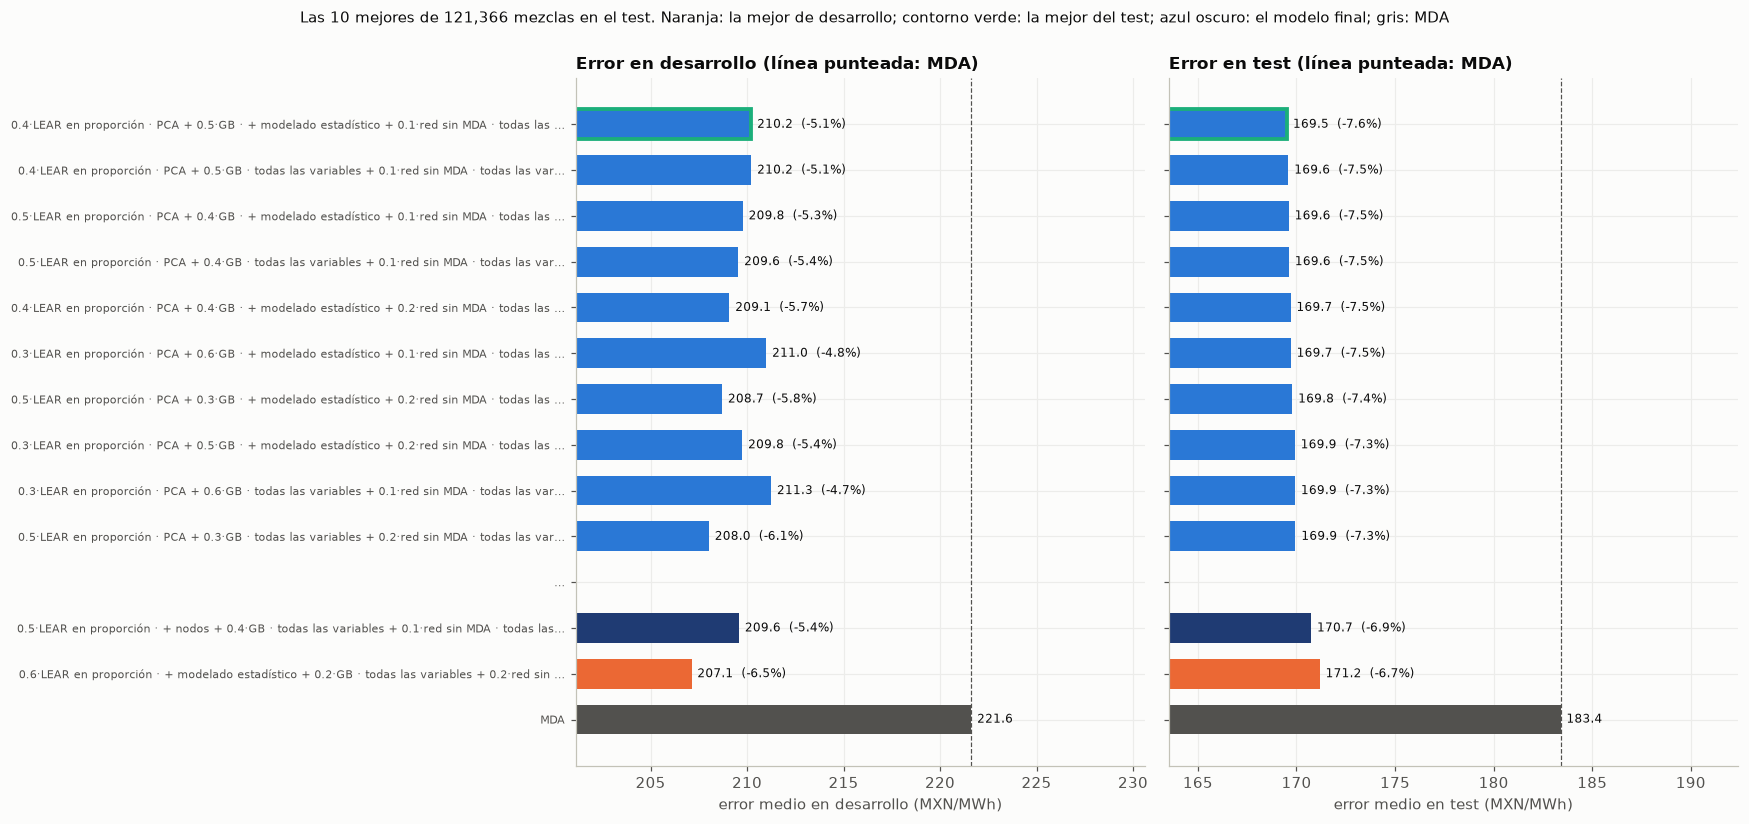

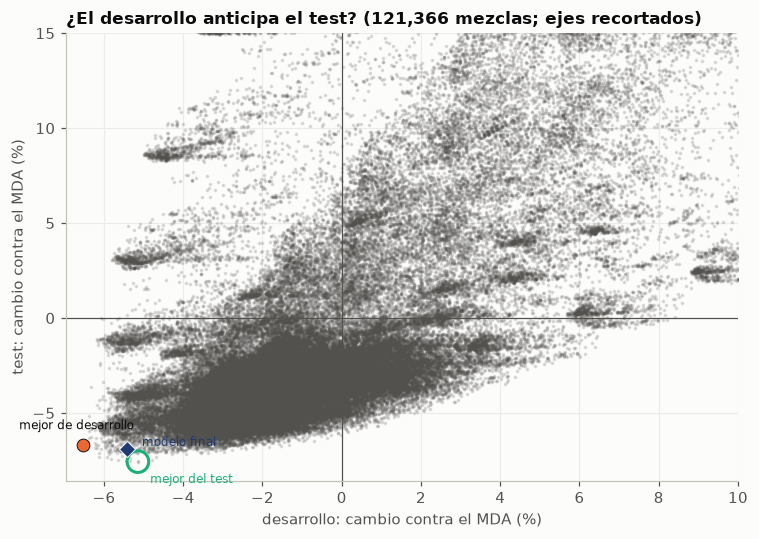

In [3]:
# Las 10 mejores mezclas del test, el modelo final y la mejor de desarrollo, con su error (MXN/MWh) en desarrollo (izquierda) y en el test (derecha).
# Naranja: la mejor de desarrollo (error medio); contorno verde: la mejor del test; azul oscuro: el modelo final; gris: MDA
filas = [nom(r) for r in ORDEN_T[:10]] + ['…'] + [nom(r) for r in SEL_R[10:]] + ['MDA']
corto = lambda s: s if len(s) <= 95 else s[:93] + '…'
T = TP.reindex([f for f in filas if f != '…'])
fig, axs = plt.subplots(1, 2, figsize=(16, 0.42 * len(filas) + 1.6), sharey=True)
for ax, per, col_mae, col_pct, idx in ((axs[0], 'desarrollo', 'MAE desarrollo', 'desarrollo vs MDA (%)', DEV), (axs[1], 'test', 'MAE test', 'test vs MDA (%)', TEST)):
    for y_, f_ in enumerate(filas):
        if f_ == '…': continue
        v, c_ = T.loc[f_, col_mae], T.loc[f_, col_pct]
        col = ps.NARANJA if f_ == nom(R_DEV) else (ps.GRIS if f_ == 'MDA' else ('#1f3b73' if f_ == FINAL_N else ps.AZUL))
        ax.barh(y_, v, color=col, height=0.65, edgecolor=ps.AQUA if f_ == nom(R_TEST) else 'none', linewidth=2.5)
        ax.text(v + 0.3, y_, f'{v:.1f}' + ('' if f_ == 'MDA' else f'  ({c_:+.1f}%)'), va='center', fontsize=8)
    ax.axvline(md_(X, idx), color=ps.GRIS, lw=0.8, ls='--'); ax.set_xlim(T[col_mae].min() - 6, T[col_mae].max() + 9)
    ax.set_xlabel(f'error medio en {per} (MXN/MWh)'); ax.set_title(f'Error en {per} (línea punteada: MDA)')
axs[0].set_yticks(range(len(filas)), [corto(f) for f in filas], fontsize=7); axs[0].invert_yaxis()
fig.suptitle(f'Las 10 mejores de {len(CANDS):,} mezclas en el test. Naranja: la mejor de desarrollo; contorno verde: la mejor del test; azul oscuro: el modelo final; gris: MDA', fontsize=10, y=0.995)
fig.tight_layout(); fig.savefig(FIG / '11_conjunto_test.png'); plt.show()
# ¿El desarrollo anticipa el test? Cada punto es una mezcla: su cambio contra el MDA en desarrollo (x) y en el test (y)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(MZ['desarrollo'], MZ['test'], s=2, color=ps.GRIS, alpha=0.15, rasterized=True)
ax.scatter(MZ['desarrollo'][R_TEST], MZ['test'][R_TEST], s=200, facecolors='none', edgecolors=ps.AQUA, lw=2, zorder=4)
ax.scatter(MZ['desarrollo'][R_DEV], MZ['test'][R_DEV], color=ps.NARANJA, s=70, zorder=5, ec='#0b0b0b', lw=0.6)
rf_ = ELEG['peor mes']; ax.scatter(MZ['desarrollo'][rf_], MZ['test'][rf_], color='#1f3b73', marker='D', s=55, zorder=5, ec='white', lw=0.6)
ax.annotate('mejor de desarrollo', (MZ['desarrollo'][R_DEV], MZ['test'][R_DEV]), xytext=(-4, 10), textcoords='offset points', fontsize=8, ha='center')
ax.annotate('mejor del test', (MZ['desarrollo'][R_TEST], MZ['test'][R_TEST]), xytext=(8, -14), textcoords='offset points', fontsize=8, color=ps.AQUA)
ax.annotate('modelo final', (MZ['desarrollo'][rf_], MZ['test'][rf_]), xytext=(10, 2), textcoords='offset points', fontsize=8, color='#1f3b73')
ax.axhline(0, color=ps.GRIS, lw=0.8); ax.axvline(0, color=ps.GRIS, lw=0.8); ax.set_xlim(MZ['desarrollo'].quantile(0.001) - 1, 10); ax.set_ylim(MZ['test'].min() - 1, 15)
ax.set_xlabel('desarrollo: cambio contra el MDA (%)'); ax.set_ylabel('test: cambio contra el MDA (%)'); ax.set_title(f'¿El desarrollo anticipa el test? ({len(CANDS):,} mezclas; ejes recortados)')
fig.tight_layout(); fig.savefig(FIG / '11_desarrollo_vs_test.png'); plt.show()

Las barras muestran las 10 mejores mezclas del test, el modelo final (azul oscuro) y la mejor de desarrollo por error medio (naranja), en desarrollo (izquierda) y en el test (derecha); el contorno verde marca la mejor del test. El dispersograma pone las 121,366 mezclas.

La mejor del test, 0.4·LEAR en proporción con PCA + 0.5·GB con modelado estadístico + 0.1·red sin MDA con todas las variables (−7.6%), ocupaba el lugar 2,190 en desarrollo. La mejor de desarrollo por error medio (0.6·LEAR en proporción con modelado estadístico + 0.2·GB con todas las variables + 0.2·red sin MDA con todas las variables; −6.5%) queda en el lugar 341 del test (−6.7%). El modelo final queda en el lugar 116 (−6.9%). Las diez mejores del test son todas mezclas de LEAR en proporción y GB con una pequeña parte de la red sin MDA. La correlación entre los dos órdenes es 0.64.

El modelo con el mejor puntaje en desarrollo no es el mejor del test, y entre tantas candidatas siempre habrá alguna que en el test salga mejor por suerte. Lo que importa es que el criterio de elección lleve, solo con desarrollo, a una mezcla que se comporte bien al implementarla en tiempo real. Eso se compara a continuación.

## 3. Cómo elegir el modelo: cuatro criterios con los meses de desarrollo

Cada criterio califica a las 121,366 mezclas usando solo los seis meses de desarrollo y elige a la de menor calificación. Se comparan cuatro, todos sobre el cambio del error contra el MDA (%):

- **Error medio:** el promedio de todo el desarrollo, el criterio usado al principio del proyecto.
- **Mediana de los meses:** el cambio de un mes típico.
- **Peor mes:** el mayor cambio en un solo mes.
- **Tendencia:** el cambio que se esperaría el mes siguiente si continúa la tendencia de los seis meses.

En la figura, cada punto es una mezcla: su calificación de desarrollo contra su cambio en el test. En naranja está la que elige el criterio y con un aro verde la mejor del test.

,mezcla elegida,desarrollo vs MDA (%),test vs MDA (%),lugar en el test,correlación con el test (Spearman)
error medio,0.6·LEAR en proporción · + modelado estadístic...,-6.541455,-6.660968,341,0.641707
mediana de los meses,0.5·LEAR en proporción · + modelado estadístic...,-6.18458,-1.118666,81486,0.713417
peor mes,0.5·LEAR en proporción · + nodos + 0.4·GB · to...,-5.429784,-6.897985,116,0.729001
tendencia,0.7·GB · + nodos + 0.2·GB · + exógenas + 0.1·T...,-1.306234,-4.785456,17591,0.767908


la mejor del test: 0.4·LEAR en proporción · PCA + 0.5·GB · + modelado estadístico + 0.1·red sin MDA · todas las variables (-7.6%)


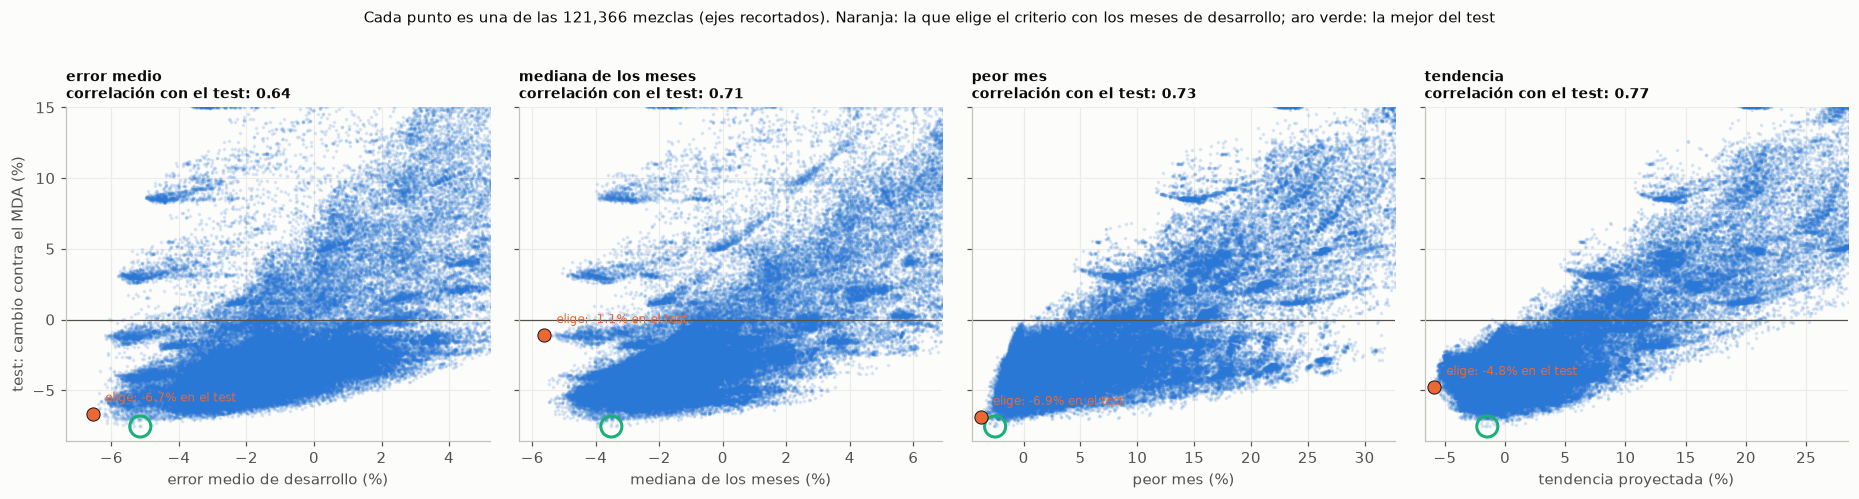

In [4]:
# Cuatro criterios para elegir una mezcla usando solo los meses de desarrollo, aplicados a todas las candidatas. Para cada uno: qué mezcla elige,
# cómo le va en el test y qué tanto su calificación ordena a las mezclas como el test
SEL = pd.DataFrame({c: {'mezcla elegida': nom(r), 'desarrollo vs MDA (%)': MZ['desarrollo'][r], 'test vs MDA (%)': MZ['test'][r], 'lugar en el test': lugar(MZ['test'], r),
                        'correlación con el test (Spearman)': spearmanr(CAL[c], MZ['test'])[0]} for c, r in ELEG.items()}).T
display(SEL); SEL.to_csv(REP / '11_criterios_eleccion.csv')
print(f"la mejor del test: {nom(R_TEST)} ({MZ['test'][R_TEST]:+.1f}%)")
NOMC = {'error medio': 'error medio de desarrollo (%)', 'mediana de los meses': 'mediana de los meses (%)', 'peor mes': 'peor mes (%)', 'tendencia': 'tendencia proyectada (%)'}
fig, axs = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
for ax, c in zip(axs, CAL):
    v = CAL[c].values; r = ELEG[c]
    ax.scatter(v, MZ['test'], s=2, color=ps.AZUL, alpha=0.12, rasterized=True)
    ax.scatter(v[R_TEST], MZ['test'][R_TEST], s=190, facecolors='none', edgecolors=ps.AQUA, lw=2, zorder=4)
    ax.scatter(v[r], MZ['test'][r], color=ps.NARANJA, s=75, ec='#0b0b0b', lw=0.6, zorder=5)
    ax.annotate(f"elige: {MZ['test'][r]:+.1f}% en el test", (v[r], MZ['test'][r]), xytext=(8, 8), textcoords='offset points', fontsize=8, color=ps.NARANJA)
    ax.set_xlim(v.min() - 0.8, np.quantile(v, 0.9)); ax.set_ylim(MZ['test'].min() - 1, 15); ax.axhline(0, color=ps.GRIS, lw=0.8)
    ax.set_title(f"{c}\ncorrelación con el test: {SEL.loc[c, 'correlación con el test (Spearman)']:.2f}", fontsize=9); ax.set_xlabel(NOMC[c])
axs[0].set_ylabel('test: cambio contra el MDA (%)')
fig.suptitle(f'Cada punto es una de las {len(CANDS):,} mezclas (ejes recortados). Naranja: la que elige el criterio con los meses de desarrollo; aro verde: la mejor del test', fontsize=10, y=1.02)
fig.tight_layout(); fig.savefig(FIG / '11_criterios_eleccion.png', bbox_inches='tight'); plt.show()

| Criterio | Mezcla elegida | Desarrollo | Test | Lugar en el test |
|---|---|---|---|---|
| Error medio | 0.6·LEAR en proporción (estadístico) + 0.2·GB (todas) + 0.2·red sin MDA (todas) | −6.5% | −6.7% | 341 |
| Mediana de los meses | 0.5·LEAR en proporción (estadístico) + 0.2·GB (exógenas) + 0.3·red sin MDA (PCA) | −6.2% | −1.1% | 81,486 |
| **Peor mes** | **0.5·LEAR en proporción (nodos) + 0.4·GB (todas) + 0.1·red sin MDA (todas)** | −5.4% | **−6.9%** | **116** |
| Tendencia | 0.7·GB (nodos) + 0.2·GB (exógenas) + 0.1·TiDE (PCA) | −1.3% | −4.8% | 17,591 |

La correlación entre la calificación de desarrollo y el cambio en el test, entre todas las mezclas, es 0.64 para el error medio, 0.71 para la mediana, 0.73 para el peor mes y 0.77 para la tendencia.

El error medio lo influyen los movimientos extremos y las fluctuaciones no uniformes, algo natural en datos de precios, donde hay cambios abruptos de un mes a otro: elige una mezcla que gana mucho en julio y agosto (−7.9% y −11.2%) y menos en los meses siguientes. La mediana describe un mes típico pero ignora los meses malos, y por eso elige una mezcla con la red sin MDA con PCA, que en desarrollo pierde en diciembre y en el test se desbarata: queda en −1.1%. El peor mes castiga justo esos meses, elige una mezcla que le gana al MDA de manera pareja en los seis meses de desarrollo (de −3.8% a −10.8%) y es la que mejor se comporta en el test, a 0.7 puntos de la mejor posible. La tendencia ordena bien a las mezclas en general, pero con seis meses su pendiente es ruidosa y la que elige queda lejos.

Se adopta el peor mes. Se puede leer como el criterio que busca el modelo que nunca pierde mucho contra el MDA en un mes: protege el peor caso, y por eso su ventaja en desarrollo se traslada bien al test.

## 4. El modelo final, elegido con el peor mes

In [5]:
# El modelo final (peor mes) contra la mejor mezcla de desarrollo (error medio), la elegida por la mediana y la mejor del test
DOS = {'elegido por el error medio': R_DEV, 'elegido por la mediana de los meses': ELEG['mediana de los meses'], 'elegido por el peor mes (modelo final)': ELEG['peor mes'], 'mejor del test (se sabe después)': R_TEST}
display(pd.DataFrame({k: {'mezcla': nom(r), 'MAE desarrollo': md_(pron(r), DEV), 'desarrollo vs MDA (%)': cambio(pron(r), DEV), 'MAE test': md_(pron(r), TEST),
                          'test vs MDA (%)': cambio(pron(r), TEST), 'meses de test que gana (de 6)': meses_mejor(pron(r)),
                          'p (Giacomini–White)': gw_test(fd(Y, TEST), fd(pron(r), TEST), fd(X, TEST))['p']} for k, r in DOS.items()}).round(3))

,elegido por el error medio,elegido por la mediana de los meses,elegido por el peor mes (modelo final),mejor del test (se sabe después)
mezcla,0.6·LEAR en proporción · + modelado estadístic...,0.5·LEAR en proporción · + modelado estadístic...,0.5·LEAR en proporción · + nodos + 0.4·GB · to...,0.4·LEAR en proporción · PCA + 0.5·GB · + mode...
MAE desarrollo,207.124053,207.914963,209.587752,210.222769
desarrollo vs MDA (%),-6.541455,-6.18458,-5.429784,-5.143252
MAE test,171.17708,181.341265,170.742408,169.522946
test vs MDA (%),-6.660968,-1.118666,-6.897985,-7.562931
meses de test que gana (de 6),5,4,5,5
p (Giacomini–White),0.000956,0.164435,0.000278,0.000257


El modelo final tiene 209.6 en desarrollo (−5.4%) y 170.7 en el test (−6.9%), mejor en 5 de 6 meses. El elegido por el error medio tenía 207.1 (−6.5%) y 171.2 (−6.7%); el elegido por la mediana, 207.9 (−6.2%) y 181.3 (−1.1%); la mejor del test, 210.2 (−5.1%) y 169.5 (−7.6%).

Promete algo menos en desarrollo que la mejor por error medio y rinde algo más en el test, lo esperable de una mezcla cuya ventaja no depende de unos pocos meses. Cada modelo aprovecha de manera distinta la información (LEAR en proporción se apoya en el MDA y en los nodos; el GB elige entre todas las variables; la red sin MDA aporta errores distintos) y la mezcla combina esas perspectivas. De aquí en adelante, las figuras muestran solo el modelo final.

## 5. Cuánto se ahorra frente al MDA

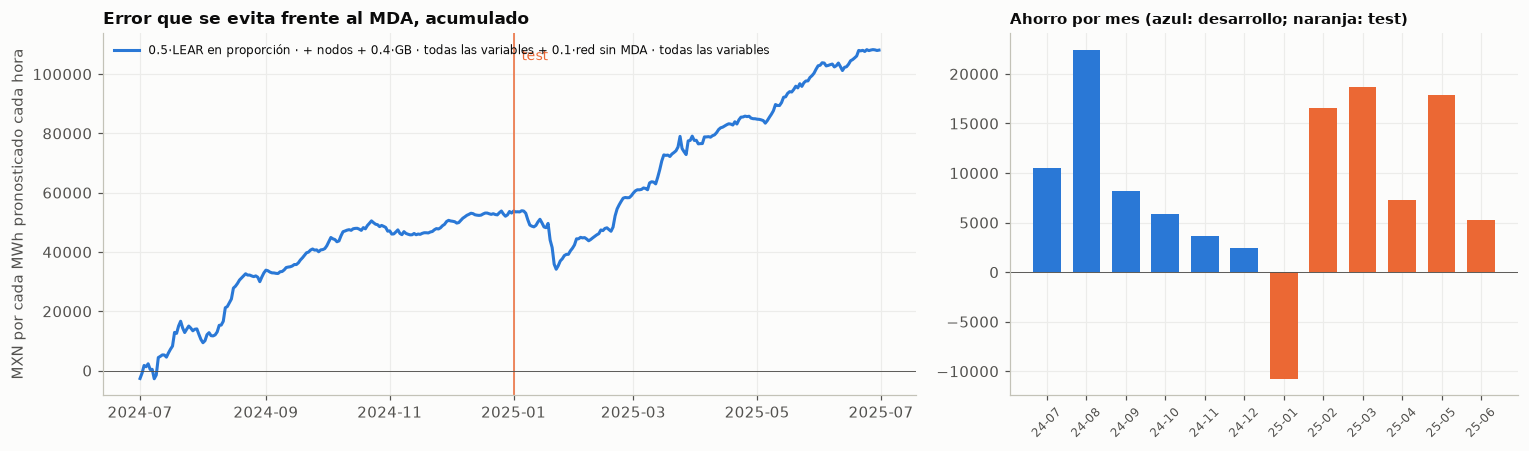

ahorro acumulado del modelo final: 53,140 en desarrollo y 54,953 en el test (MXN por MWh pronosticado cada hora, en el periodo)
meses en que el modelo final evita error: 11 de 12


In [6]:
# Ahorro acumulado frente al MDA del modelo final por la mediana: en cada hora, el error absoluto del MDA menos el del modelo, sumado día a día.
# Se lee como MXN que se dejan de equivocar por cada MWh pronosticado en cada hora. Antes del test es desarrollo; la línea marca el inicio del test
dia = lambda M: ((Y - X).abs() - (Y - M).abs()).loc[DIAS].sum(axis=1)
AH = dia(FINAL).cumsum()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axs[0]
ax.plot(AH.index, AH.values, color=ps.AZUL, lw=2, label=FINAL_N)
ax.axvline(TEST[0], color=ps.NARANJA, lw=1); ax.text(TEST[0], ax.get_ylim()[1] * 0.92, '  test', color=ps.NARANJA, fontsize=9); ax.axhline(0, color=ps.GRIS, lw=0.6)
ax.set_ylabel('MXN por cada MWh pronosticado cada hora'); ax.set_title('Error que se evita frente al MDA, acumulado'); ax.legend(fontsize=8, loc='upper left')
mes = dia(FINAL).groupby(dia(FINAL).index.strftime('%Y-%m')).sum()
axs[1].bar(range(len(mes)), mes.values, color=[ps.AZUL if m_ < '2025-01' else ps.NARANJA for m_ in mes.index], width=0.7)
axs[1].set_xticks(range(len(mes)), [m_[2:] for m_ in mes.index], rotation=45, fontsize=8); axs[1].axhline(0, color=ps.GRIS, lw=0.6)
axs[1].set_title('Ahorro por mes (azul: desarrollo; naranja: test)', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / '11_ahorro_acumulado.png'); plt.show()
print(f"ahorro acumulado del modelo final: {AH.loc[:DEV[-1]].iloc[-1]:,.0f} en desarrollo y {AH.iloc[-1] - AH.loc[:DEV[-1]].iloc[-1]:,.0f} en el test (MXN por MWh pronosticado cada hora, en el periodo)")
print('meses en que el modelo final evita error:', int((mes > 0).sum()), 'de', len(mes))

El modelo final evita 54,953 MXN por cada MWh pronosticado cada hora durante el test (181 días) y 53,140 en desarrollo. Evita error en 11 de los 12 meses; solo enero de 2025 pierde (−10,756). Los meses que más ahorra son agosto de 2024 (22,453) y marzo y mayo de 2025 (18,666 y 17,862).

El ahorro es parejo entre desarrollo y test. Enero de 2025, el mes de las heladas de Texas, en que el MDA acertó, es el único en que corregir estorbó.

## 6. ¿La ventaja se mantiene en el tiempo?

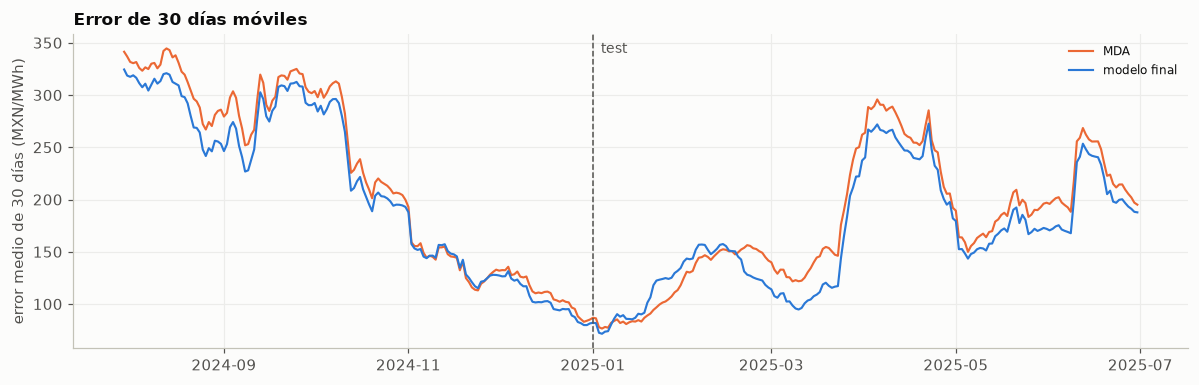

días (de 336) en que el modelo final tiene menos error móvil que el MDA: 276 | en el test: 140 de 181
ventanas en que no gana, por mes: {'2024-11': 19, '2025-01': 24, '2025-02': 17}


In [7]:
# ¿La ventaja se mantiene en el tiempo? Error medio de los últimos 30 días del modelo final y del MDA
ed = lambda M: (Y - M).abs().loc[DIAS].mean(axis=1)
RM = pd.DataFrame({'MDA': ed(X), 'modelo final': ed(FINAL)}).rolling(30).mean().dropna()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(RM.index, RM['MDA'], color=ps.NARANJA, lw=1.4, label='MDA'); ax.plot(RM.index, RM['modelo final'], color=ps.AZUL, lw=1.4, label='modelo final')
ax.axvline(TEST[0], color=ps.GRIS, lw=1, ls='--'); ax.text(TEST[0], ax.get_ylim()[1] * 0.95, '  test', color=ps.GRIS, fontsize=9)
ax.set_ylabel('error medio de 30 días (MXN/MWh)'); ax.set_title('Error de 30 días móviles'); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / '11_estabilidad.png'); plt.show()
dif = RM['MDA'] - RM['modelo final']
print(f"días (de {len(dif)}) en que el modelo final tiene menos error móvil que el MDA: {int((dif > 0).sum())} | en el test: {int((dif.loc[TEST[0]:] > 0).sum())} de {len(dif.loc[TEST[0]:])}")
m_ = dif[dif <= 0]; print('ventanas en que no gana, por mes:', m_.groupby(m_.index.strftime('%Y-%m')).size().to_dict())

Con 30 días móviles, el modelo final tiene menos error que el MDA en 276 de los 336 días que se pueden calcular (y en 140 de los 181 del test). Las 60 ventanas en que no gana son de enero (24) y febrero de 2025 (17, la ventana arrastra el mal enero) y noviembre de 2024 (19).

La ventaja es estable la mayor parte del tiempo, con baches en noviembre de 2024 y al inicio de 2025.

## 7. Dónde gana y dónde pierde

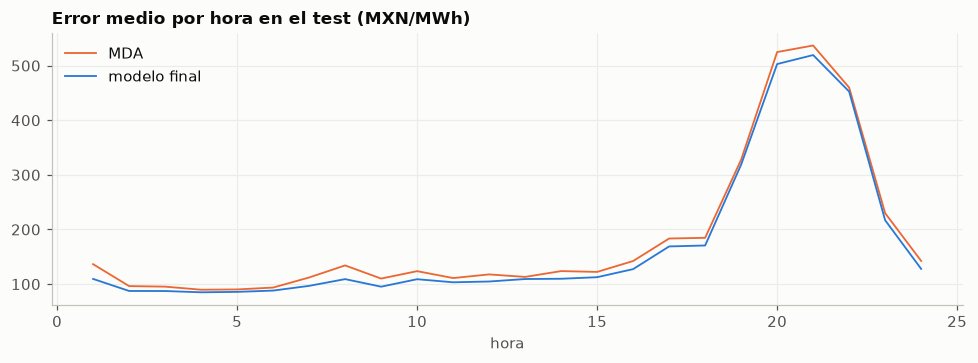

hora,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
MDA,136.5,96.3,95.3,89.7,90.2,93.6,112.1,134.2,110.1,123.7,...,122.3,142.2,183.4,184.7,327.8,524.8,536.8,459.8,229.8,142.4
modelo final,109.5,87.4,87.3,85.0,85.7,88.1,96.7,109.1,95.2,108.9,...,112.6,127.4,168.9,170.7,318.7,502.9,519.3,452.5,216.9,127.9
modelo final vs MDA (%),-19.8,-9.3,-8.4,-5.3,-4.9,-5.9,-13.7,-18.7,-13.5,-11.9,...,-7.9,-10.4,-7.9,-7.6,-2.8,-4.2,-3.3,-1.6,-5.6,-10.2


MDA  modelo final  días  \
tipo de día con pico (MTR > 3000)  571.1         577.7    18   
            sin pico               140.6         125.8   163   
calendario  feriado                 91.0          82.1     4   
            fin de semana          117.8          96.6    52   
            laboral                213.6         204.4   125   
mes         2025-01                124.1         138.6    31   
            2025-02                133.8         109.1    28   
            2025-03                258.1         233.1    31   
            2025-04                192.1         182.0    30   
            2025-05                193.0         169.0    31   
            2025-06                195.1         187.7    30   

                                   modelo final vs MDA (%)  
tipo de día con pico (MTR > 3000)                      1.2  
            sin pico                                 -10.5  
calendario  feriado                                   -9.8  
            fin de semana                            -17.9  
            laboral                                   -4.3  
mes         2025-01                                   11.6  
            2025-02                                  -18.4  
            2025-03                                   -9.7  
            2025-04                                   -5.3  
            2025-05                                  -12.4  
            2025-06                                   -3.8

In [8]:
# Dónde gana y dónde pierde el modelo final: por hora, por tipo de día, por calendario y por mes (test)
E = {'MDA': (Y - X).abs().loc[TEST], 'modelo final': (Y - FINAL).abs().loc[TEST]}
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, col in zip(E, (ps.NARANJA, ps.AZUL)): ax.plot(range(1, 25), E[k].mean().values, color=col, label=k)
ax.set_title('Error medio por hora en el test (MXN/MWh)'); ax.set_xlabel('hora'); ax.legend(); fig.tight_layout(); fig.savefig(FIG / '11_mae_hora.png'); plt.show()
hora = pd.DataFrame({k: v.mean() for k, v in E.items()}); hora['modelo final vs MDA (%)'] = 100 * (hora['modelo final'] / hora['MDA'] - 1); display(hora.round(1).T)
regimen = pd.Series('laboral', index=TEST); regimen[TEST.dayofweek >= 5] = 'fin de semana'; regimen[feriados_mx(TEST).values == 1] = 'feriado'
t = pd.DataFrame({k: v.mean(axis=1) for k, v in E.items()})
etq = np.where(pico, 'con pico (MTR > 3000)', 'sin pico'); mes_ = t.index.strftime('%Y-%m')
GR = pd.concat({'tipo de día': t.groupby(etq).mean(), 'calendario': t.groupby(regimen).mean(), 'mes': t.groupby(mes_).mean()})
GR['días'] = pd.concat([t.groupby(etq).size(), t.groupby(regimen).size(), t.groupby(mes_).size()]).values
GR['modelo final vs MDA (%)'] = 100 * (GR['modelo final'] / GR['MDA'] - 1)
display(GR.round(1)); GR.round(2).to_csv(REP / '11_por_regimen.csv')

El error se concentra en la noche (horas 19 a 22), con 330 a 540 MXN/MWh, y ahí el modelo mejora poco (entre −1.6% y −4.2%). Donde más mejora es en la madrugada y la mañana (hora 1, −19.8%; horas 7 y 8, −13.7% y −18.7%) y en la hora 24 (−10.2%). En el test:

- **Por tipo de día:** gana 10.5% en días sin pico y pierde 1.2% en días con pico.
- **Por calendario:** gana 17.9% en fines de semana, 9.8% en feriados (solo 4 días) y 4.3% en días laborales.
- **Por mes:** gana en 5 de 6, de 3.8% en junio a 18.4% en febrero, y pierde 11.6% en enero.

El modelo aprende los días y horas en que el MDA se equivoca de forma predecible, sobre todo los de poca demanda. Donde está la mayor parte del error, la noche y los picos, hace poco, y cuando el MDA acierta, como en enero, corregir cuesta.

## 8. Intervalos y picos

In [9]:
# Intervalos 10–90 en desarrollo y en el test: los cuantiles condicionados al MDA, los mismos entrenados con 64 nodos y una referencia sencilla
QS = (0.1, 0.9); SP = Yt - Xt
emp = lambda q: pd.DataFrame({d: SP.loc[f2.TRAIN_START:d - pd.Timedelta(days=8)].quantile(q).values for d in DIAS}, index=SP.columns).T
QB = pickle.loads((CACHE / 'q_Q_base_G0pG2.pkl').read_bytes())
QQ = {'cuantiles condicionados al MDA': {q: inv_s(QB[q]) for q in QS}, 'los mismos, entrenados con 64 nodos': RED['GB de cuantiles con la red'],
      'referencia: MDA + cuantiles históricos del error': {q: inv_s(emp(q)) for q in QS}}
rows = {}
for nombre, Q in QQ.items():
    for per, idx in [('desarrollo', DEV), ('test', TEST)]:
        yv = Y.loc[idx].values; lo, hi = Q[0.1].loc[idx].values, Q[0.9].loc[idx].values
        rows[(nombre, per)] = {'horas dentro del intervalo (meta 80%)': 100 * np.mean((yv >= lo) & (yv <= hi)), 'anchura mediana (MXN/MWh)': np.median(hi - lo),
                               'pérdida de cuantiles (menor es mejor)': np.mean([gb2.pinball(yv, Q[q].loc[idx].values, q) for q in QS])}
TQ = pd.DataFrame(rows).T.round(1); display(TQ); TQ.to_csv(REP / '11_intervalos_test.csv')
PQ = QQ['cuantiles condicionados al MDA']
# Picos en el test: los mismos clasificadores del notebook 10, y la cobertura de los intervalos en días con y sin pico
yp = picos.etiqueta(c0)
PP = {k: picos.clasificar(c0, TEST, v) for k, v in {'climatología por mes': 'clima', 'solo el máximo del MDA': 'solo_mda', 'gradient boosting con todo': 'gb'}.items()}
TPk = pd.DataFrame({k: picos.evaluar(p, yp) for k, p in PP.items()}).T[['AUC', 'Brier', 'Brier_ref_tasa', 'picos', 'aciertos_p50', 'falsas_p50']]
TPk = TPk.rename(columns={'Brier_ref_tasa': 'Brier con la tasa real del periodo', 'aciertos_p50': 'picos con P > 0.5', 'falsas_p50': 'falsas alarmas con P > 0.5'})
display(TPk.astype(float).round(3)); TPk.to_csv(REP / '11_picos_test.csv')
print(f'horas del test con MDA > 3000: {int((X.loc[TEST] > 3000).values.sum())}')
dp = yp.loc[TEST]; filas = {}
for sub, ix in [('todos', TEST), ('días con pico', dp.index[dp == 1]), ('días sin pico', dp.index[dp == 0])]:
    a, l, h = Y.loc[ix].values, PQ[0.1].loc[ix].values, PQ[0.9].loc[ix].values
    filas[sub] = {'días': len(ix), 'cobertura 10–90 (meta 80%)': 100 * np.mean((a >= l) & (a <= h)), 'horas sobre el cuantil 90 (meta 10%)': 100 * np.mean(a > h)}
display(pd.DataFrame(filas).T.round(1))

horas dentro del intervalo (meta 80%)  \
cuantiles condicionados al MDA                   desarrollo                                   80.9   
                                                 test                                         84.4   
los mismos, entrenados con 64 nodos              desarrollo                                   77.4   
                                                 test                                         81.1   
referencia: MDA + cuantiles históricos del error desarrollo                                   88.2   
                                                 test                                         83.3   

                                                             anchura mediana (MXN/MWh)  \
cuantiles condicionados al MDA                   desarrollo                      411.9   
                                                 test                            415.2   
los mismos, entrenados con 64 nodos              desarrollo                      334.5   
                                                 test                            353.1   
referencia: MDA + cuantiles históricos del error desarrollo                      823.4   
                                                 test                            488.0   

                                                             pérdida de cuantiles (menor es mejor)  
cuantiles condicionados al MDA                   desarrollo                                   61.1  
                                                 test                                         52.9  
los mismos, entrenados con 64 nodos              desarrollo                                   57.8  
                                                 test                                         49.3  
referencia: MDA + cuantiles históricos del error desarrollo                                   84.7  
                                                 test                                         64.6

,AUC,Brier,Brier con la tasa real del periodo,picos,picos con P > 0.5,falsas alarmas con P > 0.5
climatología por mes,0.514,0.154,0.09,18.0,3.0,17.0
solo el máximo del MDA,0.692,0.094,0.09,18.0,0.0,0.0
gradient boosting con todo,0.655,0.110,0.09,18.0,5.0,15.0


horas del test con MDA > 3000: 3


,días,cobertura 10–90 (meta 80%),horas sobre el cuantil 90 (meta 10%)
todos,181.0,84.4,9.9
días con pico,18.0,51.4,46.5
días sin pico,163.0,88.0,5.8


Los cuantiles condicionados al MDA contienen el MTR en 84.4% de las horas del test (la meta es 80%) con una anchura mediana de 415 MXN/MWh. Entrenados con 64 nodos, cubren 81.1% con intervalos más angostos (353) y mejor pérdida de cuantiles (49.3 contra 52.9). La referencia sencilla cubre 83.3% con 488 de anchura. Pero en los días con pico los intervalos contienen el valor real solo 51.4% de las veces, y 46.5% de las horas quedan sobre el cuantil 90.

Los picos siguen sin anticiparse: el mejor separador, el máximo del MDA, tiene AUC 0.69, pero solo 3 horas del test tuvieron un MDA mayor a 3,000, así que no marca ningún pico con 50%. El gradient boosting con todo tiene AUC 0.66 y marca 5 de los 18 picos a cambio de 15 falsas alarmas; ninguno le gana a conocer la tasa real de picos en probabilidad (Brier 0.094 y 0.110, contra 0.09).

Se confirma lo del notebook 09: con lo que se sabe en *d−1*, los picos no se pueden anticipar, y los intervalos subestiman el riesgo justo ahí. Con 17 meses de historia, cada tipo de evento raro (ola de calor con MDA alto, alertas de CENACE, heladas de Texas) aparece una sola vez, y no hay con qué aprenderlo ni validarlo.

## 9. El pronóstico por nodo

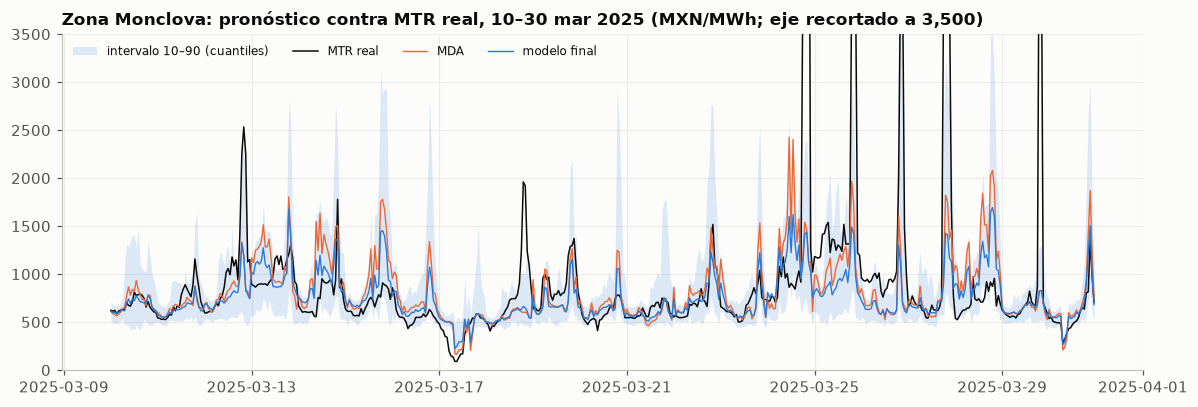

,MAE modelo final,MAE MDA del nodo,diferencia media con la zona
06AEO-115,171.2,184.0,2.4
06AHM-400,170.6,182.8,-1.0
06FRO-115,170.4,182.9,-2.0
06GRA-115,171.2,184.0,2.1
06MON-115,170.6,183.3,-0.9
06MON-230,170.6,183.3,-0.9
06RGS-115,170.8,183.5,0.2
06TKS-115,170.4,183.0,-1.8
06XOC-115,171.1,183.9,1.7


In [10]:
# El pronóstico de zona se pasa a cada nodo sumando su diferencia media con la zona (por pérdidas), estimada con 2024, antes del test
mtr, mda = cargar_largo(); nodos = sorted(mtr.nodo.unique())
g = pd.date_range('2025-03-10', '2025-03-30'); ts = pd.date_range(g[0], periods=len(g) * 24, freq='h')
serie = lambda M: M.loc[g].stack().values
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ts, serie(PQ[0.1]), serie(PQ[0.9]), color=ps.AZUL, alpha=.15, lw=0, label='intervalo 10–90 (cuantiles)')
ax.plot(ts, serie(Y), color='#0b0b0b', lw=1.0, label='MTR real'); ax.plot(ts, serie(X), color=ps.NARANJA, lw=.9, label='MDA'); ax.plot(ts, serie(FINAL), color=ps.AZUL, lw=.9, label='modelo final')
ax.set_ylim(0, 3500); ax.set_title('Zona Monclova: pronóstico contra MTR real, 10–30 mar 2025 (MXN/MWh; eje recortado a 3,500)'); ax.legend(ncol=4, loc='upper left', fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '11_pronostico_vs_real.png'); plt.show()
off = {n: float((matriz(mtr, nodo=n) - Y).loc['2024-01-01':'2024-12-31'].values.mean()) for n in nodos}
filas = {}
for n in nodos:
    Yn = matriz(mtr, nodo=n); Pn = FINAL + off[n]
    filas[n] = {'MAE modelo final': mae(fd(Yn, TEST), fd(Pn, TEST)), 'MAE MDA del nodo': mae(fd(Yn, TEST), fd(matriz(mda, nodo=n), TEST)), 'diferencia media con la zona': off[n]}
TNod = pd.DataFrame(filas).T.round(1); display(TNod); TNod.to_csv(REP / '11_por_nodo.csv')

Los 9 nodos tienen errores casi idénticos: el modelo final da entre 170.4 y 171.2 en cada uno, contra 182.8 a 184.0 del MDA del nodo. La diferencia media de cada nodo con la zona es de 2.4 MXN/MWh como máximo, muy chica frente al error.

Pronosticar una sola serie de zona y trasladarla a cada nodo con su diferencia media funciona igual de bien en los 9 nodos (notebook 02).

## Conclusiones

1. **El modelo final le gana al MDA fuera de muestra.** La mezcla 0.5·LEAR en proporción con nodos + 0.4·GB con todas las variables + 0.1·red sin MDA con todas las variables obtiene 170.7 MXN/MWh en el test contra 183.4 del MDA: 6.9% menos error, mejor en 5 de 6 meses, *p* < 0.001. En desarrollo tenía −5.4%, así que no se deteriora al salir de la muestra. Evita unos 55,000 MXN por cada MWh pronosticado cada hora en el semestre, con 11 de 12 meses a favor desde julio de 2024.
2. **Cada modelo aprovecha distinto la información, y por eso conviene mezclar versiones de modelos diferentes.** Las decisiones de la escalera mejoraron a unos modelos y empeoraron a otros, de modo que cada versión se especializó en algo distinto. Entre 121,366 mezclas de 2 y 3 modelos, las mejores juntan a LEAR en proporción, al GB y una pequeña parte de la red sin MDA, que sola pierde contra el MDA pero mezclada compensa los errores de las demás.
3. **Cómo elegir importa.** El error medio de desarrollo, usado al principio, lo influyen los movimientos extremos y las fluctuaciones no uniformes, naturales en datos con cambios abruptos de un mes a otro. La mediana de los meses ignora los meses malos y elige una mezcla inestable (−1.1% en el test). El peor mes castiga esos meses y elige una mezcla que gana parejo en desarrollo y queda en el lugar 116 de 121,366 en el test, a 0.7 puntos de la mejor posible (−7.6%). Se puede leer como el criterio que busca el modelo cuyo pronóstico nunca se aleja mucho del MDA para mal: protege el peor caso. Con él se volvió a correr toda la elección, y hay una buena convergencia entre desarrollo y test (−5.4% y −6.9%).
4. **Consideraciones sobre la elección.** Versiones anteriores del proyecto revisaron el test al cerrar cada etapa. El criterio del peor mes se escogió entre cuatro criterios después de compararlos con el test, y la mezcla se eligió entre 121,366 candidatas con solo seis meses de desarrollo. Ninguna de las dos cosas invalida el resultado, pero hacen que el −6.9% pueda ser optimista si no se comprueba que el criterio se sostenga al entrenar con un periodo más largo o con datos nuevos. Además, los hiperparámetros dentro de cada modelo se escogieron con el error medio, que era la suposición inicial; con el nuevo criterio convendría volver a escogerlos con el peor mes y reentrenar.
5. **Lo que se sostiene es mezclar LEAR en proporción con el GB.** El MDA como ancla es lo que más ayudó a todos (sin él, de 36% a 43% peor). El comportamiento de cada modelo en la escalera responde a su forma de funcionar: el GB aprovecha los ejemplos extra y elige entre variables, LEAR se satura con muchas columnas y las redes memorizan con pocos datos.
6. **Qué información importa.** Pesa sobre todo el MDA con su historial de error y lo que describe cómo se mueve el precio. Las variables externas aportan poco y según el modelo (combustibles y clima a LEAR, estado del sistema e información pública al GB).
7. **Límites.** El error se concentra en la noche y en los picos, donde el modelo hace poco; los picos no se anticipan con lo que se sabe en *d−1* y los intervalos cubren solo la mitad de las horas de los días con pico. Enero de 2025 muestra el costo de corregir cuando el MDA acierta.

**Direcciones futuras.**
- **Depender menos del MDA.** Hoy los modelos corrigen sobre todo en torno al MDA. Sería mejor que su información no determinara tanto y que un modelo entrenado con más instancias aprenda el comportamiento del sistema y genere series distintas, con más variabilidad, para aproximar el MTR sin sobreajustarse al MDA.
- **Anticipar los picos.** Es lo más importante que sigue pendiente, ya que ahí está gran parte del error y un modelo que anticipe cuándo habrá picos podría ganar un porcentaje grande.
- **Confirmar el criterio de elección** con un periodo de entrenamiento más largo o con los meses nuevos de 2025, y **volver a escoger los hiperparámetros de cada modelo con el peor mes**, reentrenando los modelos.
- **Dónde invertir.** Modelar cómo cambia el precio en el tiempo y cómo se equivoca el MDA con más ejemplos, la memoria del error y la combinación de modelos. Las variables externas aportan menos y distinto según el modelo; conviene explorarlas un poco, sin invertir demasiado tiempo.
- **Qué haría falta.** Información que el MDA no tenía al cerrarse y que hoy no es pública con anticipación: demanda real y despacho antes de *d* (CENACE los publica unos 14 días después), o registrar hacia adelante la demanda en tiempo real. Y más historia, para que los eventos raros se repitan y se puedan validar.